# UTK Police Department — Flock Search Audit Analysis

How does the University of Tennessee Police Department (UTPD) use Flock ALPR searches, and what reasons do officers give?

**Input:** `./new_normalizations/UTPD_categorized.csv` (one row per audit-log entry, with `reason_normalized` and `reason_category` from `norm_template.ipynb`)

**What this notebook covers**
1. Load and deduplicate (the same search appears in up to 11 source audits)
2. Data coverage: which months are usable
3. Search volume over time
4. Stated reasons, plus a UTPD-specific split of "Routine" into *patrol* vs *test/system*
5. UTPD's structured `Offense - Purpose` reason format
6. Test searches and repeatedly searched plates
7. User accounts
8. When searches happen (hour × weekday, football home games)
9. Search scope: time window, cameras searched, out-of-state filters
10. Overlap with Knoxville PD searches
11. Exports and findings

> **Read before interpreting:** these records come from *other agencies'* network audits that happen to log UTPD's searches of their cameras. Monthly **volume** reflects which audits were obtained as much as how often UTPD searched, so the reason analysis leans on **shares**. Each row is a search, not a crime, stop, or arrest, and the reason is free text typed or picked by the officer.

In [1]:
import json
import re
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

DATA_PATH  = "./new_normalizations/UTPD_categorized.csv"
KNOX_PATH  = "./Datasets/Knoxville.csv"          # used only in Section 10
OUT_DIR    = "./analysis_output/utpd"
LOCAL_TZ   = "America/New_York"                  # Knoxville is in Eastern time
WINDOW     = ("2025-01", "2026-05")              # analysis window, justified in Section 2
MIN_N      = 100                                 # months with fewer reasoned searches are masked in share plots
SHOW_NAMES = False                               # officer names are pseudonymised as "Account NN" unless True

os.makedirs(OUT_DIR, exist_ok=True)

# Same chart styling as murfreesboro_trends.ipynb so the city notebooks look alike
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#c9c8c2"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 8,
})
pd.set_option("display.max_columns", 40, "display.width", 160, "display.max_colwidth", 60)

## 1. Load and deduplicate

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
print(f"Raw rows: {len(raw):,}   (org: {raw['org_name'].unique().tolist()})")
raw["has_reason"] = raw["reason"].fillna("").str.strip().ne("")
print(f"Rows with a reason: {raw['has_reason'].sum():,}   rows where the source audit left it blank: {(~raw['has_reason']).sum():,}")
print("\nNote: every row in the 'REDACTED' category is a row with no reason at all:")
print(pd.crosstab(raw["has_reason"], raw["reason_category"].eq("REDACTED"),
                  rownames=["has reason"], colnames=["category == REDACTED"]))

Raw rows: 13,935   (org: ['University of Tennessee TN PD'])
Rows with a reason: 9,537   rows where the source audit left it blank: 4,398

Note: every row in the 'REDACTED' category is a row with no reason at all:
category == REDACTED  False  True 
has reason                        
False                     0   4398
True                   9537      0


### 1a. Why the Murfreesboro dedup key isn't enough here
`murfreesboro_trends.ipynb` treats rows as duplicates when they share **timestamp + reason + time window**. For UTPD that misses most duplicates, because many source audits *drop the reason column*. The same search then appears once with its reason and again with a blank reason, and the two copies don't match on `reason`.

The check below groups on **timestamp + searched time window only** and looks inside each group.

In [3]:
TIME_KEY = ["search_time_utc", "start_timeframe_utc", "end_timeframe_utc"]
REASON_KEY = TIME_KEY[:1] + ["reason"] + TIME_KEY[1:]

grp = raw.groupby(TIME_KEY, dropna=False)
g = pd.DataFrame({
    "copies": grp.size(),
    "reasons": grp["reason"].nunique(),
    "blank_copies": grp["has_reason"].apply(lambda s: (~s).sum()),
    "plates": grp["license_plate_hash"].nunique(),
})
print(f"Unique by Murfreesboro key (time + reason + window): {raw.drop_duplicates(REASON_KEY).shape[0]:,}")
print(f"Unique by time + window:                            {len(g):,}")
print(f"  groups mixing a reasoned copy and a blank copy:   {((g.reasons >= 1) & (g.blank_copies >= 1)).sum():,}")
print(f"  groups with >1 distinct reason text:              {(g.reasons > 1).sum():,}")
print(f"  groups with >1 distinct plate hash:               {(g.plates > 1).sum():,}   (0 = no evidence two different searches collide)")
print("\nCopies per search:")
print(g["copies"].value_counts().sort_index().to_string())

Unique by Murfreesboro key (time + reason + window): 8,432
Unique by time + window:                            4,654
  groups mixing a reasoned copy and a blank copy:   3,722
  groups with >1 distinct reason text:              56
  groups with >1 distinct plate hash:               0   (0 = no evidence two different searches collide)

Copies per search:
copies
1      590
2     1444
3     1442
4      940
5       18
6        4
8       26
9       53
10      42
11      11
12      63
13      19
14       2


In [4]:
# What do the groups with >1 distinct reason look like?
multi = g[g.reasons > 1].index
ex = raw.set_index(TIME_KEY).loc[multi].reset_index()
ex["source"] = ex["sources"].apply(lambda s: json.loads(s)[0]["source_url"].split("/")[-1])
print("Reason texts inside multi-reason groups (top 10):")
print(ex["reason"].value_counts().head(10).to_string())
print("\nSource behind the generic 'Investigation' copies:")
print(ex.loc[ex["reason"] == "Investigation", "source"].value_counts().to_string())

Reason texts inside multi-reason groups (top 10):
reason
Wanted Person (Arrest Warrant/Fugitive) -    22
Wanted Person (Arrest Warrant/Fugitive)      22
Test                                         15
Motor Vehicle Theft/Stolen -                 13
Motor Vehicle Theft/Stolen                   11
Image Download                               10
Investigation                                 8
test                                          5
Stolen Property Offenses -                    5
INVESTIGATION                                 4

Source behind the generic 'Investigation' copies:
source
riverside-county-ca-jan2022-aug2026    8


Nearly all of the multi-reason groups are a real reason (`test`, `Image Download`, `Stolen`...) plus a generic **"Investigation"** copy from one source audit (Riverside County CA), which appears to fill that value in for every search. Different-case spellings (`INVESTIGATION` / `Investigation`) normalise to the same text anyway. No group contains two different plate hashes.

**Rule used:** one row per `timestamp + time window`. Within a group, the row ranked first is the one that has a reason, and it is not the generic Riverside "Investigation" when another reason exists. Every other field takes the first non-blank value across the group's copies, so details redacted in one audit are filled in from another (e.g. `E.` → `E. Sas`).

In [5]:
r = raw.copy()
r["_n_reasons"] = r.groupby(TIME_KEY, dropna=False)["reason"].transform("nunique")
r["_generic"] = (r["reason"].eq("Investigation") & (r["_n_reasons"] > 1)).astype(int)
r["_name_len"] = r["name"].fillna("").str.len()
detail_cols = ["name", "license_plate_hash", "search_type", "total_devices_searched", "case_number", "filters"]
r["_detail"] = r[detail_cols].notna().sum(axis=1)
r["_n_sources"] = r["sources"].apply(lambda s: len(json.loads(s)) if isinstance(s, str) else 0)
r["_src_files"] = r["sources"].apply(lambda s: [x.get("filename") for x in json.loads(s)] if isinstance(s, str) else [])

r = r.sort_values(["has_reason", "_generic", "_name_len", "_detail"], ascending=[False, True, False, False])
keep_cols = [c for c in raw.columns if c not in TIME_KEY]
df = r.groupby(TIME_KEY, dropna=False, sort=False)[keep_cols].first().reset_index()   # first non-null per column
src = r.groupby(TIME_KEY, dropna=False, sort=False)["_src_files"].sum().apply(lambda l: sorted(set(l)))
df = df.merge(src.rename("source_files").reset_index(), on=TIME_KEY, how="left")
df["n_source_files"] = df["source_files"].str.len()
df["has_reason"] = df["reason"].fillna("").str.strip().ne("")
df.loc[~df["has_reason"], "reason_category"] = "Reason Not In Source Audit"

print(f"Raw rows {len(raw):,}  →  unique searches {len(df):,}  "
      f"({1 - len(df) / len(raw):.1%} of raw rows were duplicate copies)")
print(f"Unique searches with a reason: {df['has_reason'].sum():,} ({df['has_reason'].mean():.1%}); "
      f"without: {(~df['has_reason']).sum():,}")

Raw rows 13,935  →  unique searches 4,654  (66.6% of raw rows were duplicate copies)
Unique searches with a reason: 4,654 (100.0%); without: 0


### 1b. Derived fields

In [6]:
for col in ["search_time_utc", "start_timeframe_utc", "end_timeframe_utc"]:
    df[col.replace("_utc", "")] = pd.to_datetime(df[col], utc=True, errors="coerce").dt.tz_convert(LOCAL_TZ)
for col in ["total_devices_searched", "total_networks_searched"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df.loc[df["total_devices_searched"] == 0, "total_devices_searched"] = np.nan   # 0 = redacted in some audits

df = df.dropna(subset=["search_time"]).sort_values("search_time").reset_index(drop=True)
df["month"]   = df["search_time"].dt.tz_localize(None).dt.to_period("M")
df["date"]    = df["search_time"].dt.date
df["hour"]    = df["search_time"].dt.hour
df["weekday"] = df["search_time"].dt.day_name()
df["window_hours"] = (df["end_timeframe"] - df["start_timeframe"]).dt.total_seconds() / 3600
df.loc[df["window_hours"] < 0, "window_hours"] = np.nan          # a few rows have end before start
df["rn"] = df["reason_normalized"].fillna("")

# Officer accounts: names are already truncated in the audits; pseudonymise by volume rank
rank = df["name"].value_counts()
alias = {n: (n if SHOW_NAMES else f"Account {i:02d}") for i, n in enumerate(rank.index, 1)}
df["user"] = df["name"].map(alias).fillna("(name not in audit)")

print(f"First search: {df['search_time'].min():%Y-%m-%d}   last search: {df['search_time'].max():%Y-%m-%d}")
print(f"Named accounts: {df['name'].nunique()}   searches with a name: {df['name'].notna().mean():.1%}")

First search: 2022-11-12   last search: 2026-07-22
Named accounts: 34   searches with a name: 38.1%


## 2. Data coverage: which months can we trust?
The bars show unique searches per month. The line shows how many distinct source audit files contributed to that month. When the two move together, swings in volume come from **which audits were obtained**, not necessarily from UTPD behaviour.

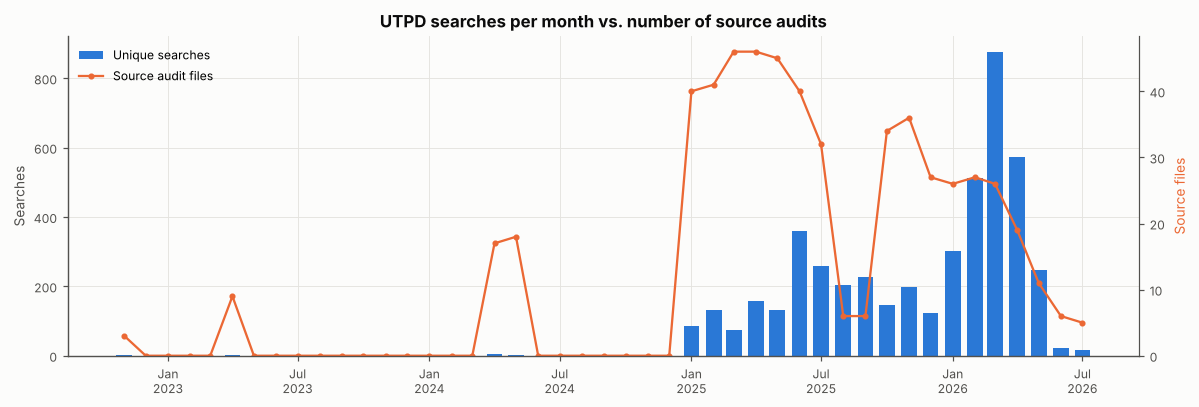

Correlation between monthly searches and source-file count (active months): r = 0.14


,searches,with_reason,source_files,reason_share
2022-11,1,1,3,1.0
2023-04,1,1,9,1.0
2024-04,6,6,17,1.0
2024-05,2,2,18,1.0
2025-01,86,86,40,1.0
2025-02,133,133,41,1.0
2025-03,73,73,46,1.0
2025-04,159,159,46,1.0
2025-05,132,132,45,1.0
2025-06,359,359,40,1.0


In [7]:
all_months = pd.period_range(df["month"].min(), df["month"].max(), freq="M")
coverage = pd.DataFrame({
    "searches": df.groupby("month").size(),
    "with_reason": df.groupby("month")["has_reason"].sum(),
    "source_files": df.explode("source_files").groupby("month")["source_files"].nunique(),
}).reindex(all_months, fill_value=0)
coverage["reason_share"] = (coverage["with_reason"] / coverage["searches"]).round(3)

ct = coverage.copy(); ct.index = ct.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(ct.index, ct["searches"], width=22, color=BLUE, label="Unique searches")
ax2 = ax.twinx(); ax2.plot(ct.index, ct["source_files"], color=ORANGE, marker="o", ms=3, lw=1.5, label="Source audit files")
ax2.set_ylabel("Source files", color=ORANGE); ax2.spines["right"].set_visible(True); ax2.grid(False); ax2.set_ylim(bottom=0)
ax.set_title("UTPD searches per month vs. number of source audits"); ax.set_ylabel("Searches")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()

active = coverage[coverage["searches"] > 0]
print(f"Correlation between monthly searches and source-file count (active months): "
      f"r = {active['searches'].corr(active['source_files']):.2f}")
coverage[coverage["searches"] > 0]

Two things stand out. First, **after deduplication every search has a reason**: each blank-reason row was a copy of a search that another audit recorded with its reason. The 4,398 "REDACTED" rows in the categorised file were all duplicates. Second, volume does **not** simply track how many audits cover a month (r is low). Aug–Sep 2025 come from only 6 source files yet hold 200+ searches each, while 2026 has fewer source files than early 2025 but more searches. Volume is still only a lower bound, because a search that no obtained audit happened to log is invisible.

Before 2025 there are only a few stray months (Nov 2022, Apr 2023, Apr–May 2024), and June–July 2026 hold a few dozen searches. The rest of the notebook uses **Jan 2025 – May 2026** (17 months), which contains almost all of the data. Within that window, reason-based charts mask any month with fewer than `MIN_N` reasoned searches.

In [8]:
months = pd.period_range(WINDOW[0], WINDOW[1], freq="M")
w  = df[df["month"].between(pd.Period(WINDOW[0]), pd.Period(WINDOW[1]))].copy()
wr = w[w["has_reason"]].copy()                      # used for every reason-based analysis
n_rec = wr.groupby("month").size().reindex(months, fill_value=0)
print(f"Searches in window: {len(w):,} of {len(df):,} ({len(w)/len(df):.1%})")
print(f"  with a recorded reason: {len(wr):,}")
print(f"  months masked in share plots (<{MIN_N} reasoned searches): {[str(m) for m in n_rec[n_rec < MIN_N].index] or 'none'}")

Searches in window: 4,605 of 4,654 (98.9%)
  with a recorded reason: 4,605
  months masked in share plots (<100 reasoned searches): ['2025-01', '2025-03']


## 3. Search volume over time

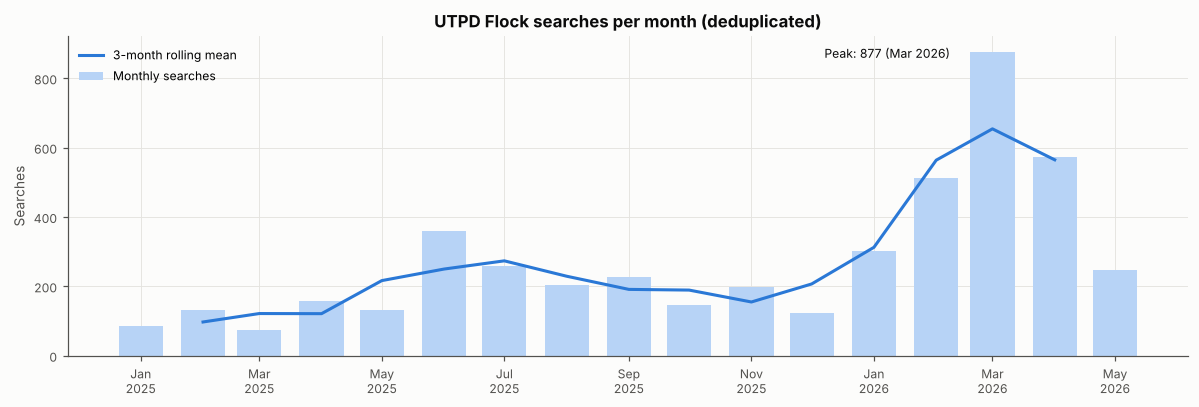

Active days: 390   median searches per active day: 6   busiest day: 2026-03-11 (266 searches)
Busiest day share of its month: 30%


In [9]:
monthly = w.groupby("month").size().reindex(months, fill_value=0)
mt = monthly.copy(); mt.index = mt.index.to_timestamp()
roll = mt.rolling(3, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(mt.index, mt.values, width=22, color="#b7d3f6", label="Monthly searches")
ax.plot(roll.index, roll.values, color=BLUE, label="3-month rolling mean")
ax.set_title("UTPD Flock searches per month (deduplicated)"); ax.set_ylabel("Searches")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
pk = mt.idxmax()
ax.annotate(f"Peak: {mt.max():,} ({pk:%b %Y})", (pk, mt.max()), xytext=(-110, -4),
            textcoords="offset points", fontsize=8, color=INK)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

per_day = w.groupby("date").size()
print(f"Active days: {per_day.size:,}   median searches per active day: {per_day.median():.0f}   busiest day: "
      f"{per_day.idxmax()} ({per_day.max()} searches)")
print(f"Busiest day share of its month: {per_day.max() / monthly[pd.Period(per_day.idxmax(), 'M')]:.0%}")

## 4. Stated reasons
### 4a. Category mix (deduplicated, in window, reasoned searches only)

In [10]:
cat_tot = wr["reason_category"].value_counts()
pd.DataFrame({"searches": cat_tot, "share": (cat_tot / len(wr)).map("{:.1%}".format)})

,searches,share
reason_category,,
Traffic / Crash,1780,38.7%
Routine / Administrative / Test,1341,29.1%
Stolen Vehicle / MVT,312,6.8%
Malformed / Unintelligible,288,6.3%
Warrant / Wanted Person,277,6.0%
Property Crime,116,2.5%
General Investigation,115,2.5%
Drug Investigation,96,2.1%
Violent / Sexual Crime,88,1.9%


### 4b. UTPD adjustment: split "Routine" into patrol vs. test/system
Two things in the shared categoriser hide what UTPD is doing:

- **`p` / `P` / `pp` are classed "Malformed / Unintelligible".** UTPD writes `p.` and `pat` as the purpose suffix for patrol everywhere else (`traffic infraction - p.`, `... - pat`), so a bare `p` is almost certainly *patrol*. Section 6 shows the same accounts use `p` and `patrol` interchangeably.
- **"Routine / Administrative / Test" lumps patrol together with system tests.** For an accountability question these are very different. A *test* searches the department's own test plate. A *patrol* search is a real vehicle search that names no offense.

The original column is left untouched. A new column, `utpd_category`, is used from here on.

Where the two new groups came from (original category → new):
utpd_category                    Patrol (no offense stated)  Test / System
reason_category                                                           
Malformed / Unintelligible                              274              0
Routine / Administrative / Test                        1160            181


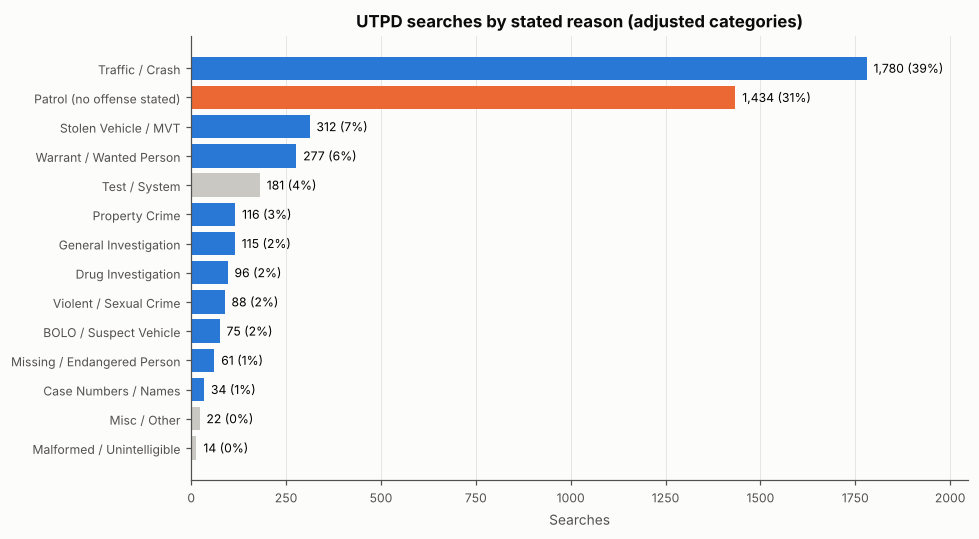

,searches,share
utpd_category,,
Traffic / Crash,1780,38.7%
Patrol (no offense stated),1434,31.1%
Stolen Vehicle / MVT,312,6.8%
Warrant / Wanted Person,277,6.0%
Test / System,181,3.9%
Property Crime,116,2.5%
General Investigation,115,2.5%
Drug Investigation,96,2.1%
Violent / Sexual Crime,88,1.9%


In [11]:
PATROL_RE = r"^(?:p|pp|p\.|pat|patro|patrol|on patrol)$"
TEST_RE   = r"^(?:test|image download|daytime search for best result)$"

def utpd_category(row):
    rn = row["rn"]
    if re.fullmatch(PATROL_RE, rn):  return "Patrol (no offense stated)"
    if re.fullmatch(TEST_RE, rn):    return "Test / System"
    return row["reason_category"]

for frame in (df, w, wr):
    frame["utpd_category"] = frame.apply(utpd_category, axis=1)

moved = pd.crosstab(wr["reason_category"], wr["utpd_category"])
moved = moved.loc[:, ["Patrol (no offense stated)", "Test / System"]]
print("Where the two new groups came from (original category → new):")
print(moved[moved.sum(axis=1) > 0].to_string())

ucat = wr["utpd_category"].value_counts()
utbl = pd.DataFrame({"searches": ucat, "share": (ucat / len(wr))})
fig, ax = plt.subplots(figsize=(9, 5))
p = utbl.sort_values("searches")
colors = [ORANGE if "Patrol" in c else (MUTED if c in ("Test / System", "Malformed / Unintelligible", "Misc / Other") else BLUE) for c in p.index]
ax.barh(p.index, p["searches"], color=colors)
for i, (v, s) in enumerate(zip(p["searches"], p["share"])):
    ax.text(v, i, f"  {v:,} ({s:.0%})", va="center", fontsize=8)
ax.set_title("UTPD searches by stated reason (adjusted categories)"); ax.set_xlabel("Searches")
ax.grid(axis="y", visible=False); ax.margins(x=0.15)
plt.tight_layout(); plt.show()
utbl.style.format({"share": "{:.1%}"})

### 4c. Most common reason labels

In [12]:
top_reasons = (wr.groupby(["utpd_category", "rn"]).size().rename("searches")
                 .reset_index().sort_values("searches", ascending=False).head(25))
top_reasons["share"] = (top_reasons["searches"] / len(wr)).map("{:.1%}".format)
top_reasons.rename(columns={"rn": "reason_normalized"}).reset_index(drop=True)

,utpd_category,reason_normalized,searches,share
0,Patrol (no offense stated),patrol,977,21.2%
1,Traffic / Crash,traffic infraction - pat,677,14.7%
2,Traffic / Crash,traffic infraction -,634,13.8%
3,Patrol (no offense stated),p,273,5.9%
4,Stolen Vehicle / MVT,motor vehicle theft/stolen -,203,4.4%
5,Warrant / Wanted Person,wanted person (arrest warrant/fugitive) -,193,4.2%
6,Traffic / Crash,traffic infraction - patrol,176,3.8%
7,Test / System,test,172,3.7%
8,Patrol (no offense stated),pat,171,3.7%
9,General Investigation,investigation,81,1.8%


### 4d. Monthly share by category
Each small panel shows one category on the same y-axis. The thin line is the monthly share and the thick line is a 3-month rolling mean.

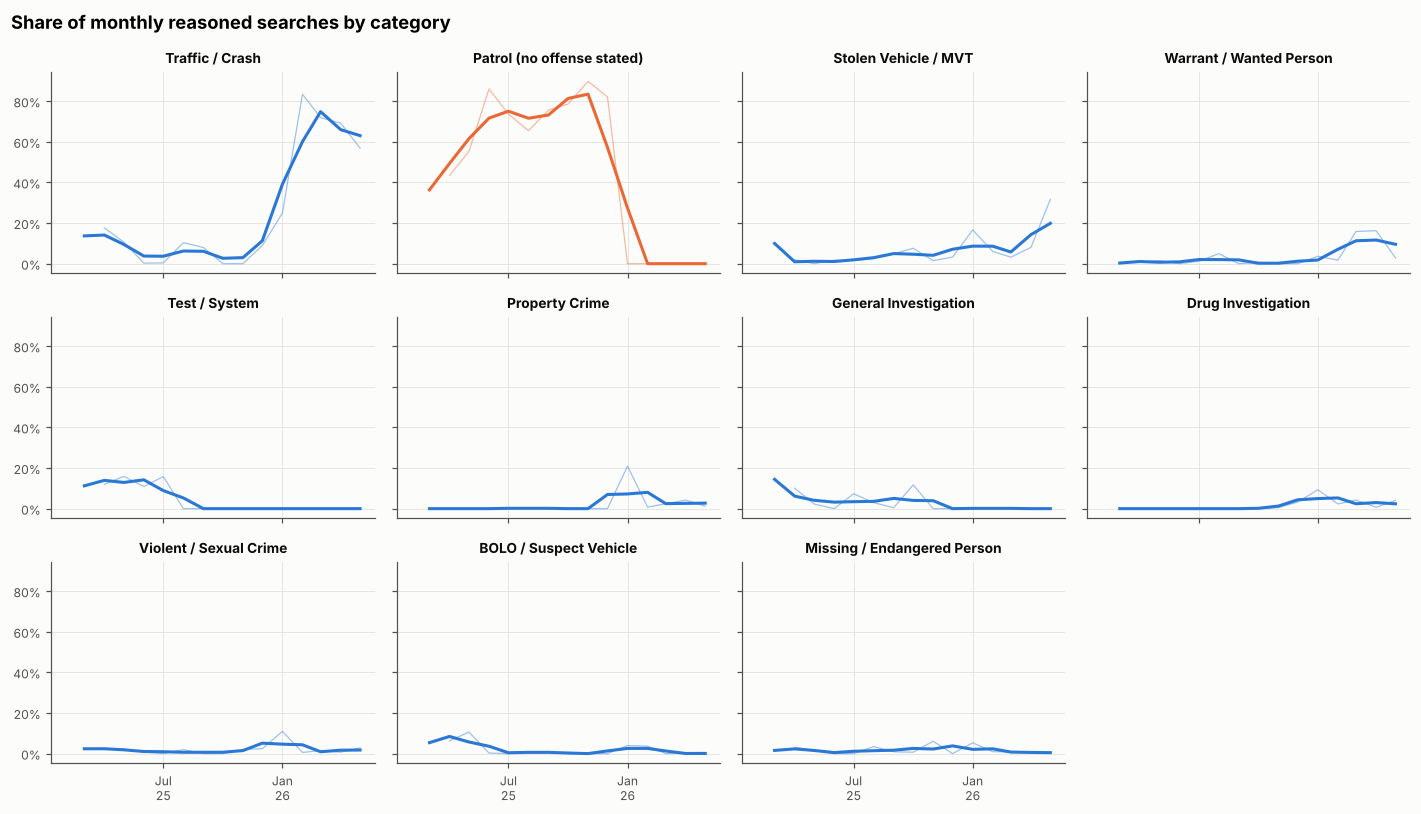

In [13]:
share = pd.crosstab(wr["month"], wr["utpd_category"], normalize="index").reindex(months)
share[n_rec < MIN_N] = np.nan
share = share[ucat.index]
share = share.loc[:, ucat / ucat.sum() >= 0.01]                 # drop categories under 1%
share_t = share.copy(); share_t.index = share_t.index.to_timestamp()

ncol = 4; nrow = int(np.ceil(share.shape[1] / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 2.5 * nrow), sharex=True, sharey=True)
for ax, cat in zip(axes.flat, share_t.columns):
    s = share_t[cat]
    c = ORANGE if "Patrol" in cat else BLUE
    ax.plot(s.index, s.values, color=c, lw=0.8, alpha=0.45)
    ax.plot(s.index, s.rolling(3, center=True, min_periods=2).mean(), color=c, lw=2)
    ax.set_title(cat, fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%y"))
for ax in axes.flat[share.shape[1]:]:
    ax.set_visible(False)
fig.suptitle("Share of monthly reasoned searches by category", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

### 4e. Did officers state an offense?
This tracks the share of reasoned searches that name an actual offense (theft, warrant, crash...). The other groups are bare *patrol*, *test/system*, case-number-only, and unintelligible text. Watch January 2026, then see Section 5 for why the line jumps there.

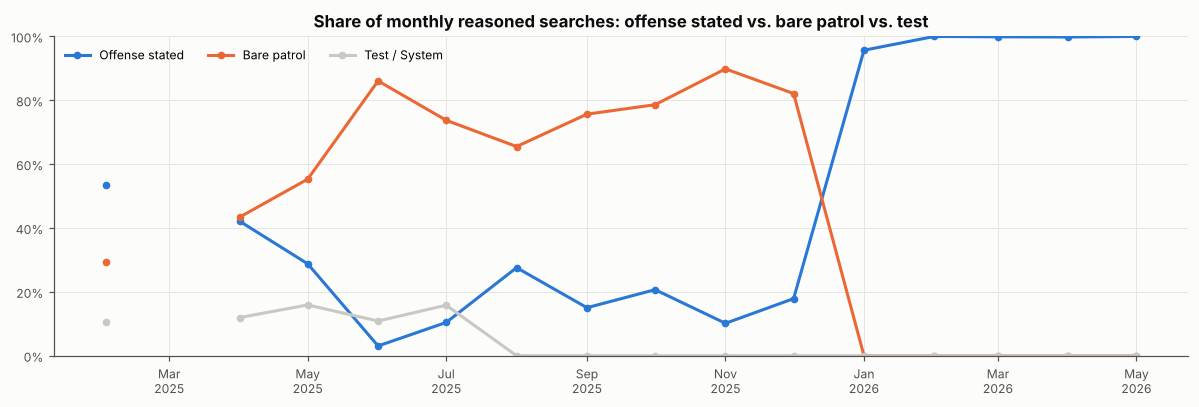

Whole window — offense stated: 63.4%, bare patrol: 31.1%, test/system: 3.9%


,Offense stated,Bare patrol,Test / System
2025-01,NaN,NaN,NaN
2025-02,0.534,0.293,0.105
2025-03,NaN,NaN,NaN
2025-04,0.421,0.434,0.119
2025-05,0.288,0.553,0.159
2025-06,0.031,0.861,0.109
2025-07,0.104,0.737,0.158
2025-08,0.276,0.655,0.000
2025-09,0.150,0.757,0.000
2025-10,0.207,0.786,0.000


In [14]:
NON_OFFENSE = {"Patrol (no offense stated)", "Test / System", "Case Numbers / Names",
               "Malformed / Unintelligible", "Misc / Other", "Routine / Administrative / Test"}
for frame in (df, w, wr):
    frame["has_offense"] = ~frame["utpd_category"].isin(NON_OFFENSE)

trend = pd.DataFrame({
    "Offense stated": wr.groupby("month")["has_offense"].mean(),
    "Bare patrol": wr.groupby("month")["utpd_category"].apply(lambda s: s.eq("Patrol (no offense stated)").mean()),
    "Test / System": wr.groupby("month")["utpd_category"].apply(lambda s: s.eq("Test / System").mean()),
}).reindex(months)
trend[n_rec < MIN_N] = np.nan
tt = trend.copy(); tt.index = tt.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 3.8))
for col, c in zip(tt.columns, [BLUE, ORANGE, MUTED]):
    ax.plot(tt.index, tt[col], color=c, marker="o", ms=4, label=col)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("Share of monthly reasoned searches: offense stated vs. bare patrol vs. test")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()
print(f"Whole window — offense stated: {wr['has_offense'].mean():.1%}, "
      f"bare patrol: {wr['utpd_category'].eq('Patrol (no offense stated)').mean():.1%}, "
      f"test/system: {wr['utpd_category'].eq('Test / System').mean():.1%}")
trend.round(3)

## 5. UTPD's structured `Offense - Purpose` format
Many UTPD reasons look like picks from a drop-down, e.g. `Traffic Infraction - Pat`, `Wanted Person (Arrest Warrant/Fugitive) - P.`, `Stolen Property Offenses - Investigation`. The part before the dash is an **offense** and the part after it is a **purpose** (patrol vs. investigation). This section parses the two halves and asks:

- When did the structured format appear?
- When an offense *is* named, is the search tied to an investigation, or done while on patrol?

In [15]:
STRUCT = re.compile(r"^(?P<offense>.+?)\s+-\s*(?P<purpose>.*)$")

def purpose_bucket(p):
    p = (p or "").strip().rstrip(".")
    if p == "":                                  return "(blank after dash)"
    if re.fullmatch(r"p|pat|patrol", p):         return "Patrol"
    if re.fullmatch(r"inv|investigation", p):    return "Investigation"
    return "Other text"

m = wr["rn"].str.extract(STRUCT)
wr["structured"] = (m["offense"].notna()
                    & ~wr["rn"].str.match(r"^\d")                       # case numbers like 25-000352
                    & ~wr["rn"].str.startswith("other image search"))    # Flock alert strings ("... - 2025-03-18t11:24z")
wr["offense_part"] = m["offense"].where(wr["structured"])
wr["purpose"] = m["purpose"].where(wr["structured"]).map(purpose_bucket, na_action="ignore")

s = wr[wr["structured"]]
print(f"Reasoned searches in Offense-Purpose format: {len(s):,} ({len(s)/len(wr):.1%})\n")
print("Purpose suffix:")
print(s["purpose"].value_counts().to_frame("searches").assign(share=lambda d: (d.searches / d.searches.sum()).map("{:.1%}".format)).to_string())

Reasoned searches in Offense-Purpose format: 2,510 (54.5%)

Purpose suffix:
                    searches  share
purpose                            
(blank after dash)      1286  51.2%
Patrol                  1134  45.2%
Other text                64   2.5%
Investigation             26   1.0%


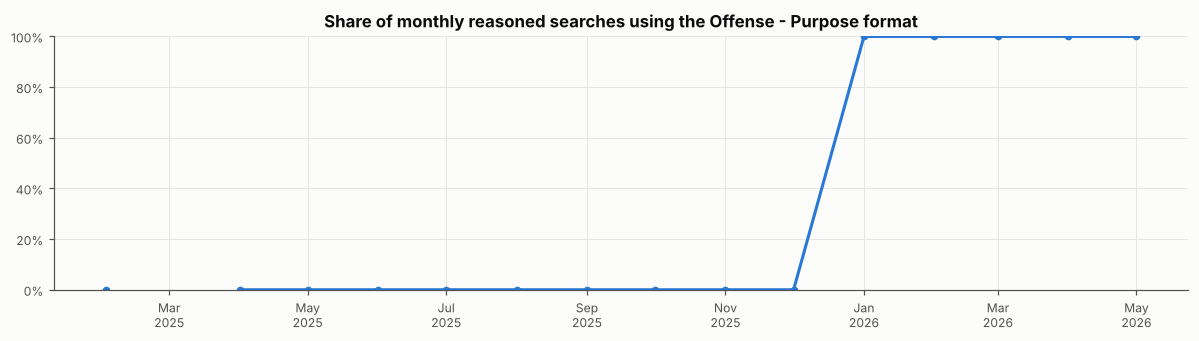

First structured reason: 2026-01-01


In [16]:
fmt = wr.groupby("month")["structured"].mean().reindex(months).where(n_rec >= MIN_N)
fmt.index = fmt.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(fmt.index, fmt.values, color=BLUE, marker="o", ms=4)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("Share of monthly reasoned searches using the Offense - Purpose format")
plt.tight_layout(); plt.show()
first_struct = s["search_time"].min()
print(f"First structured reason: {first_struct:%Y-%m-%d}")

In [17]:
# Offense × purpose: which offenses get searched "on patrol" vs. as part of an investigation?
op = pd.crosstab(s["offense_part"], s["purpose"])
op["total"] = op.sum(axis=1)
op = op.sort_values("total", ascending=False)
op["patrol share"] = (op.get("Patrol", 0) / op["total"]).map("{:.0%}".format)
op.head(15)

purpose,(blank after dash),Investigation,Other text,Patrol,total,patrol share
offense_part,,,,,,
traffic infraction,634,1,12,853,1500,57%
wanted person (arrest warrant/fugitive),193,0,8,58,259,22%
motor vehicle theft/stolen,203,0,3,27,233,12%
alcohol offenses (non-dui),4,0,0,108,112,96%
drugs/narcotics,63,4,21,5,93,5%
stolen property offenses,12,21,2,22,57,39%
burglary/breaking & entering,25,0,0,7,32,22%
obstructing the police (fleeing/eluding),13,0,0,17,30,57%
criminal motor vehicle offense (incl. road rage/reckless),21,0,2,0,23,0%


### 5b. Total "patrol" footprint
"Patrol" appears in two places: as the whole reason (`patrol`, `p`, `pat`) and as the purpose suffix of a structured reason. Adding them together gives the share of UTPD's reasoned searches that are justified *at least in part* as patrol rather than a specific investigation.

In [18]:
wr["any_patrol"] = wr["utpd_category"].eq("Patrol (no offense stated)") | wr["purpose"].eq("Patrol")
fp = pd.Series({
    "Bare patrol (no offense)": wr["utpd_category"].eq("Patrol (no offense stated)").sum(),
    "Offense named, purpose = patrol": (wr["purpose"].eq("Patrol")).sum(),
    "Everything else": (~wr["any_patrol"]).sum(),
})
print((fp / fp.sum()).map("{:.1%}".format).to_string())
print(f"\nAny patrol justification: {wr['any_patrol'].mean():.1%} of {len(wr):,} reasoned searches")
print(f"Excluding test/system searches: {wr.loc[wr['utpd_category'] != 'Test / System', 'any_patrol'].mean():.1%}")

Bare patrol (no offense)           31.1%
Offense named, purpose = patrol    24.6%
Everything else                    44.2%

Any patrol justification: 55.8% of 4,605 reasoned searches
Excluding test/system searches: 58.0%


### 5c. The January 2026 switch
The Offense - Purpose format appears all at once on **1 January 2026** and then accounts for every reason. Bare `patrol` disappears on the same day. The check below confirms this is not just a change in *which* audits we have: within the Forest Park OH audits, which cover both years, the switch happens at the same point.

So the jump in "offense stated" in Section 4e mostly reflects a **change in how reasons are entered** (an offense field that now has to be filled in), not a sudden change in why UTPD searches. The *patrol* purpose carries over: the share of searches justified at least partly as patrol drops (see `any_patrol` below) but stays large, and about half of 2026 entries leave the purpose blank after the dash.

In [19]:
wr["era"] = np.where(wr["search_time"] < pd.Timestamp("2026-01-01", tz=LOCAL_TZ), "2025 (free text)", "2026 (Offense - Purpose)")
era = wr.groupby("era").agg(
    searches=("search_time", "size"),
    structured=("structured", "mean"),
    offense_stated=("has_offense", "mean"),
    bare_patrol=("utpd_category", lambda s: s.eq("Patrol (no offense stated)").mean()),
    any_patrol=("any_patrol", "mean"),
    test_system=("utpd_category", lambda s: s.eq("Test / System").mean()),
    name_recorded=("name", lambda s: s.notna().mean()),
    night_22_06=("hour", lambda s: s.isin([22, 23, 0, 1, 2, 3, 4, 5]).mean()),
)
display(era.style.format({c: "{:.1%}" for c in era.columns if c != "searches"}))

fp = wr[wr["source_files"].apply(lambda l: any("Forest Park" in x for x in l))]
print("Forest Park OH audits only — share in Offense - Purpose format by month:")
print(fp.groupby("month")["structured"].mean().map("{:.0%}".format).to_string())
print(f"\nFirst structured reason overall: {wr.loc[wr['structured'], 'search_time'].min():%Y-%m-%d %H:%M}   "
      f"last bare patrol: {wr.loc[wr['utpd_category'] == 'Patrol (no offense stated)', 'search_time'].max():%Y-%m-%d %H:%M}")

,searches,structured,offense_stated,bare_patrol,any_patrol,test_system,name_recorded,night_22_06
era,,,,,,,,
2025 (free text),2095,0.0%,20.3%,68.4%,68.4%,8.6%,84.1%,50.1%
2026 (Offense - Purpose),2510,100.0%,99.4%,0.0%,45.2%,0.0%,0.0%,51.6%


Forest Park OH audits only — share in Offense - Purpose format by month:
month
2025-01      0%
2025-02      0%
2025-03      0%
2025-04      0%
2025-05      0%
2025-06      0%
2025-07      0%
2025-08      0%
2025-09      0%
2025-10      0%
2025-11      0%
2025-12      0%
2026-01    100%
2026-02    100%
2026-03    100%
2026-04    100%
2026-05    100%
Freq: M

First structured reason overall: 2026-01-01 00:05   last bare patrol: 2025-12-28 22:41


## 6. Test searches and repeatedly searched plates
`license_plate_hash` is a short hash of the plate searched. It is present on only part of the records because many audits redact it. A plate that is searched dozens of times by one account, almost always with reason `test`, is a **test plate**. Those rows tell us about system checks, not about anyone being tracked.

In [20]:
plates = w.dropna(subset=["license_plate_hash"])
print(f"Searches with a plate hash: {len(plates):,} ({len(plates)/len(w):.1%} of window)   distinct plates: {plates['license_plate_hash'].nunique():,}")

pt = (plates.groupby("license_plate_hash")
            .agg(searches=("search_time", "size"),
                 accounts=("user", "nunique"),
                 top_account=("user", lambda s: s.value_counts().index[0]),
                 top_reason=("rn", lambda s: s.value_counts().index[0] if s.ne("").any() else ""),
                 test_share=("utpd_category", lambda s: s.eq("Test / System").mean()),
                 days=("date", "nunique"),
                 first=("date", "min"), last=("date", "max"))
            .sort_values("searches", ascending=False))
per_plate = pt["searches"]
print(f"Plates searched once: {(per_plate == 1).mean():.0%}   2–5 times: {per_plate.between(2, 5).mean():.0%}   >5 times: {(per_plate > 5).mean():.0%}")
pt.head(12).style.format({"test_share": "{:.0%}"})

Searches with a plate hash: 1,305 (28.3% of window)   distinct plates: 369


Plates searched once: 49%   2–5 times: 40%   >5 times: 11%

,searches,accounts,top_account,top_reason,test_share,days,first,last
license_plate_hash,,,,,,,,
96c285d2,144,1,Account 05,test,100%,56,2025-02-03,2025-07-23
f1fff8e4,64,3,Account 01,p,0%,3,2025-06-06,2025-06-11
56c4d7be,42,2,Account 03,patrol,0%,1,2025-09-21,2025-09-21
511f9149,37,2,Account 01,p,3%,6,2025-07-01,2025-09-01
d449b39e,35,4,Account 01,p,0%,6,2025-05-26,2025-08-10
b84ec304,23,3,Account 02,patrol,0%,6,2025-04-20,2025-07-08
57e39e81,21,2,Account 07,patrol,0%,7,2025-04-18,2025-06-11
ff279cf6,19,6,Account 10,investigation,0%,4,2025-03-29,2025-04-07
05b42855,19,2,Account 04,patrol,0%,2,2025-06-28,2025-06-29


In [21]:
TEST_PLATES = pt[(pt["test_share"] >= 0.8) & (pt["searches"] >= 10)].index.tolist()
print(f"Plates flagged as test plates (≥80% 'test' reasons, ≥10 searches): {TEST_PLATES}")
non_test = pt.drop(TEST_PLATES)
print(f"Non-test plates searched on ≥3 different days: {(non_test['days'] >= 3).sum()}")
print("\nReasons on the most-searched non-test plates:")
for h in non_test.head(5).index:
    rs = plates.loc[plates["license_plate_hash"] == h, "rn"].replace("", "(no reason)").value_counts().head(4)
    print(f"  {h}: {non_test.loc[h, 'searches']} searches over {non_test.loc[h, 'days']} days — " +
          ", ".join(f"{k} ×{v}" for k, v in rs.items()))

Plates flagged as test plates (≥80% 'test' reasons, ≥10 searches): ['96c285d2']
Non-test plates searched on ≥3 different days: 15

Reasons on the most-searched non-test plates:
  f1fff8e4: 64 searches over 3 days — p ×58, patrol ×6
  56c4d7be: 42 searches over 1 days — patrol ×42
  511f9149: 37 searches over 6 days — p ×20, pat ×14, investigation ×2, daytime search for best result ×1
  d449b39e: 35 searches over 6 days — p ×26, patrol ×4, pat ×3, other image search from alerts page associated with alert: fled from bruce 05/24/25 251bppf - 2025-05-31t03:07:55.378z ×1
  b84ec304: 23 searches over 6 days — patrol ×16, p ×4, pat ×3


## 7. User accounts
Officer names in the audits are already truncated (e.g. `D. Vil`). They are shown here as `Account NN`, ranked by volume (set `SHOW_NAMES = True` in the first cell to see the truncated names). Names are missing on most rows because many audits redact them, and **no 2026 search carries a name** (Section 5c), so this section effectively describes 2025.

In [22]:
named = w[w["name"].notna()]
print(f"Searches with an account name in window: {len(named):,} ({len(named)/len(w):.1%})")
acct = (named.groupby("user")
              .agg(searches=("search_time", "size"),
                   reasoned=("has_reason", "sum"),
                   patrol=("utpd_category", lambda s: s.eq("Patrol (no offense stated)").sum()),
                   test=("utpd_category", lambda s: s.eq("Test / System").sum()),
                   offense=("has_offense", "sum"),
                   first=("date", "min"), last=("date", "max"))
              .sort_values("searches", ascending=False))
for c in ["patrol", "test", "offense"]:
    acct[c + " %"] = acct[c] / acct["reasoned"].replace(0, np.nan)
acct["share of named"] = acct["searches"] / acct["searches"].sum()
top3 = acct["share of named"].head(3).sum()
print(f"Named accounts: {len(acct)}   top 3 accounts = {top3:.0%} of named searches")
acct.drop(columns=["patrol", "test", "offense"]).head(15).style.format(
    {"patrol %": "{:.0%}", "test %": "{:.0%}", "offense %": "{:.0%}", "share of named": "{:.1%}"}, na_rep="–")

Searches with an account name in window: 1,762 (38.3%)
Named accounts: 34   top 3 accounts = 48% of named searches


,searches,reasoned,first,last,patrol %,test %,offense %,share of named
user,,,,,,,,
Account 01,411,411,2025-01-29,2025-11-21,99%,0%,0%,23.3%
Account 02,241,241,2025-01-27,2025-11-19,98%,1%,1%,13.7%
Account 03,200,200,2025-07-02,2025-11-19,100%,0%,0%,11.4%
Account 04,181,181,2025-04-19,2025-07-13,96%,1%,3%,10.3%
Account 05,165,165,2025-01-06,2025-07-23,0%,100%,0%,9.4%
Account 06,94,94,2025-01-07,2025-11-06,21%,0%,73%,5.3%
Account 07,66,66,2025-04-20,2025-11-16,98%,0%,2%,3.7%
Account 08,45,45,2025-02-20,2025-11-07,0%,0%,36%,2.6%
Account 09,43,43,2025-02-21,2025-09-08,0%,0%,93%,2.4%


In [23]:
# Is bare 'p' an individual habit? Which accounts write p / pat / patrol?
pat = named[named["utpd_category"] == "Patrol (no offense stated)"]
print(pd.crosstab(pat["user"], pat["rn"]).loc[lambda d: d.sum(axis=1).sort_values(ascending=False).index].head(8).to_string())

rn          on patrol    p  pat  patro  patrol  pp
user                                              
Account 01          0  252  104      1      51   0
Account 02          0    0    0      0     236   0
Account 03          0    0    0      0     200   0
Account 04          0    0    1      0     173   0
Account 07          0    2    0      0      62   1
Account 13          0    0    0      0      23   0
Account 06          0    0    2      0      18   0
Account 16          0    0    0      0      19   0


## 8. When searches happen
### 8a. Hour × weekday (Eastern time)

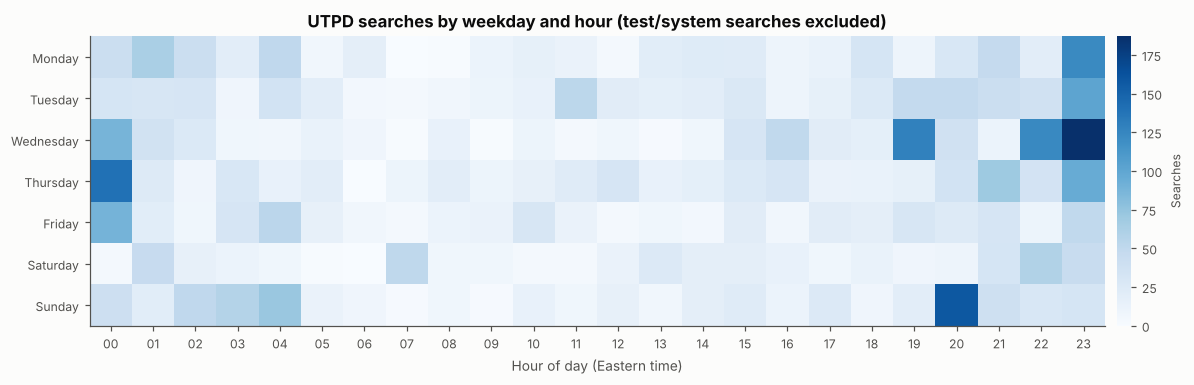

Searches 22:00–05:59: 51.5%  (8/24 = 33.3% if uniform)
Searches on weekends: 24.6%  (2/7 = 28.6% if uniform)
Busiest hour: 23:00   busiest weekday: Wednesday


In [24]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
real = w[w["utpd_category"] != "Test / System"]          # drop system tests from timing analysis
heat = pd.crosstab(real["weekday"], real["hour"]).reindex(index=order, columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_xticklabels([f"{h:02d}" for h in range(24)])
ax.set_yticks(range(7)); ax.set_yticklabels(order)
ax.set_xlabel("Hour of day (Eastern time)"); ax.grid(False)
ax.set_title("UTPD searches by weekday and hour (test/system searches excluded)")
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("Searches", fontsize=8); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

night = real["hour"].isin([22, 23, 0, 1, 2, 3, 4, 5]).mean()
print(f"Searches 22:00–05:59: {night:.1%}  (8/24 = 33.3% if uniform)")
print(f"Searches on weekends: {real['weekday'].isin(['Saturday', 'Sunday']).mean():.1%}  (2/7 = 28.6% if uniform)")
print(f"Busiest hour: {real['hour'].value_counts().idxmax():02d}:00   busiest weekday: {real['weekday'].value_counts().idxmax()}")

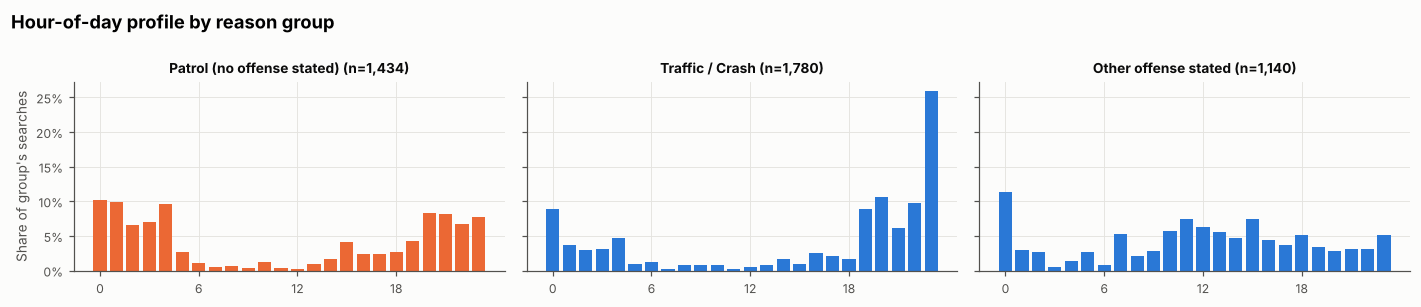

In [25]:
# Hour profile: bare patrol vs. offense-stated searches (each normalised to its own total)
rr = real[real["has_reason"]]
groups = {"Patrol (no offense stated)": rr["utpd_category"].eq("Patrol (no offense stated)"),
          "Traffic / Crash": rr["utpd_category"].eq("Traffic / Crash"),
          "Other offense stated": rr["has_offense"] & rr["utpd_category"].ne("Traffic / Crash")}
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
for ax, (name, mask) in zip(axes, groups.items()):
    h = rr.loc[mask, "hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax.bar(h.index, h.values, color=ORANGE if "Patrol" in name else BLUE, width=0.8)
    ax.set_title(f"{name} (n={mask.sum():,})", fontsize=9); ax.set_xticks([0, 6, 12, 18])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Share of group's searches")
fig.suptitle("Hour-of-day profile by reason group", fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

### 8b. Football home games (2025 season)
Neyland Stadium is on campus, so home games are UTPD's largest recurring events. The 2025 home dates below come from UT Athletics' published schedule (utsports.com, "2025 Football Schedule Dates Announced"). The comparison is home-game Saturdays vs. other Saturdays in the same Aug 30 – Nov 29 stretch.

Caveat: with 7 home games, this is a descriptive comparison, not a statistical test. Fall 2025 Saturdays are also thinly covered (several show zero searches, including the first three home games, which fall in the 6-source Aug–Sep stretch). Treat the result as "no visible game-day spike in the data we have", not as evidence that game days are quiet.

In [26]:
HOME_GAMES_2025 = pd.to_datetime(["2025-09-06", "2025-09-13", "2025-09-20", "2025-10-11",
                                  "2025-11-01", "2025-11-15", "2025-11-29"]).date
season_sats = pd.date_range("2025-08-30", "2025-11-29", freq="W-SAT").date

real_day = real.groupby("date").size()
rr_day = rr.groupby("date")
sat = pd.DataFrame(index=pd.Index(season_sats, name="saturday"))
sat["home game"] = sat.index.isin(HOME_GAMES_2025)
sat["searches"] = real_day.reindex(sat.index, fill_value=0)
sat["bare patrol"] = rr[rr["utpd_category"] == "Patrol (no offense stated)"].groupby("date").size().reindex(sat.index, fill_value=0)
sat["traffic/crash"] = rr[rr["utpd_category"] == "Traffic / Crash"].groupby("date").size().reindex(sat.index, fill_value=0)
display(sat)
summary = sat.groupby("home game")[["searches", "bare patrol", "traffic/crash"]].mean().round(1)
summary.index = summary.index.map({True: "Home-game Saturday (mean)", False: "Other Saturday (mean)"})
summary

,home game,searches,bare patrol,traffic/crash
saturday,,,,
2025-08-30,False,0,0,0
2025-09-06,True,0,0,0
2025-09-13,True,0,0,0
2025-09-20,True,0,0,0
2025-09-27,False,0,0,0
2025-10-04,False,1,1,0
2025-10-11,True,7,0,0
2025-10-18,False,3,3,0
2025-10-25,False,1,0,0


,searches,bare patrol,traffic/crash
home game,,,
Other Saturday (mean),2.3,2.1,0.0
Home-game Saturday (mean),2.4,1.4,0.0


## 9. Search scope
### 9a. How far back each search looks

In [27]:
print("Searched time window (hours):")
print(w["window_hours"].describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
bins   = [0, 1, 6, 24, 24*7, 24*31, np.inf]
labels = ["≤1h", "1–6h", "6–24h", "1–7 days", "7–31 days", ">31 days"]
w["window_bucket"] = pd.cut(w["window_hours"], bins=bins, labels=labels, include_lowest=True)
wb = pd.crosstab(w["utpd_category"].where(w["utpd_category"].isin(ucat.head(6).index), "Other"),
                 w["window_bucket"], normalize="index").reindex(columns=labels)
print("\nWindow length by category (row %):")
(wb * 100).round(0)

Searched time window (hours):
count    4557.0
mean      281.3
std       496.9
min         0.2
25%        24.0
50%       168.0
75%       336.0
90%       720.0
max      8794.0

Window length by category (row %):


window_bucket,≤1h,1–6h,6–24h,1–7 days,7–31 days,>31 days
utpd_category,,,,,,
Other,1.0,11.0,17.0,31.0,30.0,9.0
Patrol (no offense stated),0.0,3.0,22.0,49.0,17.0,9.0
Property Crime,0.0,11.0,11.0,33.0,44.0,2.0
Stolen Vehicle / MVT,0.0,20.0,33.0,23.0,25.0,0.0
Test / System,0.0,0.0,1.0,4.0,78.0,17.0
Traffic / Crash,1.0,4.0,36.0,43.0,16.0,0.0
Warrant / Wanted Person,0.0,1.0,54.0,31.0,14.0,0.0


### 9b. How many cameras each search sweeps
`total_devices_searched` takes two clearly separate values. About 20k devices is consistent with a search of shared/regional networks, and 75k+ looks like a nationwide search. The field is redacted on most rows, so this describes only the searches where it was reported.

Searches reporting device count: 1,873 (40.7%)


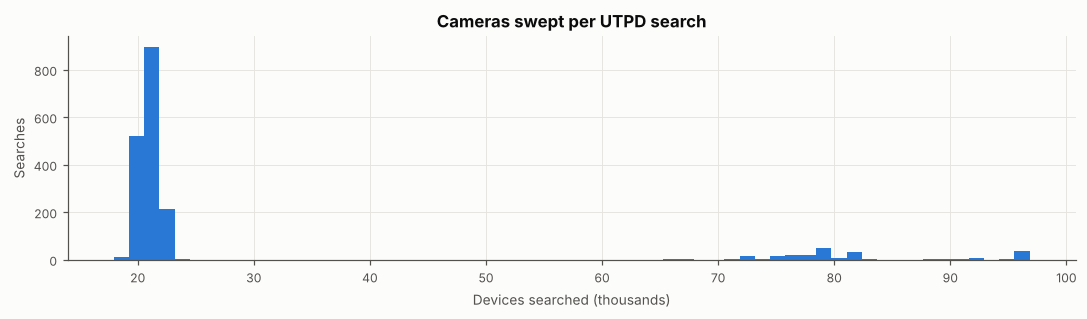

scope
<50k (regional)    87.7%
≥50k (national)    12.3%

National-scope share by category (reported rows only):
utpd_category
Test / System                  84%
Traffic / Crash                21%
Violent / Sexual Crime         15%
General Investigation          11%
Stolen Vehicle / MVT            7%
BOLO / Suspect Vehicle          6%
Property Crime                  4%
Patrol (no offense stated)      4%
Missing / Endangered Person     3%
Case Numbers / Names            0%
Warrant / Wanted Person         0%


In [28]:
dev = w["total_devices_searched"].dropna()
print(f"Searches reporting device count: {len(dev):,} ({len(dev)/len(w):.1%})")
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(dev / 1000, bins=60, color=BLUE)
ax.set_xlabel("Devices searched (thousands)"); ax.set_ylabel("Searches")
ax.set_title("Cameras swept per UTPD search")
plt.tight_layout(); plt.show()
w["scope"] = pd.cut(w["total_devices_searched"], [0, 50_000, np.inf], labels=["<50k (regional)", "≥50k (national)"])
print(w["scope"].value_counts(normalize=True).map("{:.1%}".format).to_string())
print("\nNational-scope share by category (reported rows only):")
nat = w.dropna(subset=["scope"]).groupby("utpd_category")["scope"].apply(lambda s: (s == "≥50k (national)").mean())
print(nat[w.dropna(subset=["scope"])["utpd_category"].value_counts() >= 20].sort_values(ascending=False).map("{:.0%}".format).to_string())

### 9c. Filters: out-of-state and vehicle-description searches
The `filters` field holds search filters (state, make, colour, body type) run together as one string, e.g. `pickupblacktennessee`. A filter naming another state means UTPD asked for plates from that state.

In [29]:
STATES = ["alabama", "arkansas", "georgia", "kentucky", "mississippi", "missouri", "north carolina", "northcarolina",
          "virginia", "south carolina", "southcarolina", "ohio", "indiana", "illinois", "michigan", "florida", "texas",
          "colorado", "california", "new york", "newyork", "pennsylvania", "tennessee"]
f = w["filters"].dropna().str.lower()
print(f"Searches with any filter: {len(f):,} ({len(f)/len(w):.1%})")
state_hit = f.apply(lambda s: next((st for st in STATES if st in s.replace(" ", "")), None))
print(state_hit.fillna("(no state)").value_counts().head(12).to_string())
desc = f.str.replace("|".join(STATES), "", regex=True).str.strip()
print(f"\nFilters with a vehicle description beyond state (make/colour/body): {(desc != '').sum():,}")
print("Most common description strings:", desc[desc != ""].value_counts().head(8).to_dict())

Searches with any filter: 870 (18.9%)
filters
tennessee     602
(no state)    163
michigan       29
colorado       25
georgia         8
ohio            8
texas           8
florida         6
kentucky        5
alabama         4
indiana         4
california      3

Filters with a vehicle description beyond state (make/colour/body): 353
Most common description strings: {'pickupblack': 30, 'pickup': 18, 'dodge': 16, 'suvtoyotablack': 16, 'kia': 16, 'lexus': 13, 'pickupdodgewhite': 11, 'cadillac': 10}


## 10. Overlap with Knoxville PD
UTPD's campus sits inside Knoxville PD's jurisdiction, and some UTPD reasons mention KPD directly (`hit and run kpd`, `kpd cirt vehicle of interest`). Plate hashes appear to be computed the same way across audits, so a plate hash that shows up in **both** departments' searches is a shared target. A short time gap between the two searches suggests joint work.

With roughly 370 UTPD and 3,800 KPD plate hashes, the chance of a random 8-hex-character collision is well under 1%, so matches are treated as the same plate.

In [30]:
if os.path.exists(KNOX_PATH):
    kpd = pd.read_csv(KNOX_PATH, usecols=["license_plate_hash", "search_time_utc", "reason"], dtype=str).dropna(subset=["license_plate_hash"])
    kpd["t"] = pd.to_datetime(kpd["search_time_utc"], utc=True)
    ut = df.dropna(subset=["license_plate_hash"])
    ut = ut[~ut["license_plate_hash"].isin(TEST_PLATES)]
    shared = sorted(set(ut["license_plate_hash"]) & set(kpd["license_plate_hash"]))
    print(f"UTPD plates (excl. test plates): {ut['license_plate_hash'].nunique():,}   KPD plates: {kpd['license_plate_hash'].nunique():,}   shared: {len(shared)}")

    pair = ut[ut["license_plate_hash"].isin(shared)][["license_plate_hash", "search_time", "rn", "utpd_category"]].merge(
        kpd[kpd["license_plate_hash"].isin(shared)][["license_plate_hash", "t", "reason"]], on="license_plate_hash")
    pair["gap_h"] = (pair["search_time"].dt.tz_convert("UTC") - pair["t"]).dt.total_seconds() / 3600
    closest = pair.loc[pair["gap_h"].abs().groupby(pair["license_plate_hash"]).idxmin()]
    g_abs = closest["gap_h"].abs()
    print(f"Shared plates where the two agencies searched within 1 hour: {(g_abs <= 1).sum()}   within 24 hours: {(g_abs <= 24).sum()}")
    print(f"Of the within-24h pairs, UTPD searched first in {(closest.loc[g_abs <= 24, 'gap_h'] < 0).sum()} and KPD first in {(closest.loc[g_abs <= 24, 'gap_h'] > 0).sum()}")
    print("\nUTPD reason category on shared plates (closest pair):")
    print(closest["utpd_category"].value_counts().to_string())
    display(closest.assign(gap_minutes=(closest["gap_h"] * 60).round(0))
                   .sort_values("gap_h", key=abs)[["license_plate_hash", "search_time", "rn", "reason", "gap_minutes"]]
                   .rename(columns={"rn": "UTPD reason", "reason": "KPD reason", "search_time": "UTPD search time"})
                   .head(15).reset_index(drop=True))
else:
    print(f"{KNOX_PATH} not found — skipping cross-agency overlap.")

UTPD plates (excl. test plates): 371   KPD plates: 3,836   shared: 51
Shared plates where the two agencies searched within 1 hour: 24   within 24 hours: 35
Of the within-24h pairs, UTPD searched first in 17 and KPD first in 18

UTPD reason category on shared plates (closest pair):
utpd_category
Patrol (no offense stated)    41
Warrant / Wanted Person        2
Stolen Vehicle / MVT           2
General Investigation          2
Test / System                  2
BOLO / Suspect Vehicle         1
Violent / Sexual Crime         1


,license_plate_hash,UTPD search time,UTPD reason,KPD reason,gap_minutes
0,d394e7af,2025-07-21 22:46:30-04:00,patrol,25,2.0
1,b85997c6,2025-07-25 19:13:41-04:00,pat,90,-2.0
2,ab0d8787,2025-07-08 10:42:07-04:00,investigation,stolen,2.0
3,11d41e69,2025-06-05 22:02:41-04:00,p,43,3.0
4,f77eb143,2025-02-19 22:27:02-05:00,patrol,90,3.0
5,44f24dbc,2025-08-20 00:52:50-04:00,patrol,fled,3.0
6,c77372bf,2025-11-16 12:03:32-05:00,murder suspect,62,3.0
7,1d89ece2,2025-08-20 01:14:51-04:00,patrol,25-Oct,-4.0
8,f7960ce2,2025-08-12 22:16:33-04:00,p,10-90,4.0
9,8c2c2a96,2025-08-17 10:06:28-04:00,patrol,1041,-5.0


Negative `gap_minutes` = UTPD searched first; positive = KPD searched first.

## 11. Export tables for the cross-city comparison

In [31]:
export = df.drop(columns=["source_files"]).assign(source_files=df["source_files"].str.join(";"))
export.to_csv(f"{OUT_DIR}/UTPD_deduped.csv", index=False)
pd.crosstab(w["month"], w["utpd_category"]).reindex(months, fill_value=0).to_csv(f"{OUT_DIR}/monthly_category_counts.csv")
share.to_csv(f"{OUT_DIR}/monthly_category_share.csv")
coverage.to_csv(f"{OUT_DIR}/coverage_by_month.csv")
heat.to_csv(f"{OUT_DIR}/weekday_hour_counts.csv")
op.to_csv(f"{OUT_DIR}/offense_by_purpose.csv")
pt.to_csv(f"{OUT_DIR}/plate_repeat_summary.csv")
print("Wrote:", *sorted(os.listdir(OUT_DIR)), sep="\n  ")

Wrote:
  UTPD_deduped.csv
  coverage_by_month.csv
  monthly_category_counts.csv
  monthly_category_share.csv
  offense_by_purpose.csv
  plate_repeat_summary.csv
  weekday_hour_counts.csv


## 12. Key numbers

In [32]:
kn = {
    "Raw audit rows": f"{len(raw):,}",
    "Unique searches after dedup": f"{len(df):,} ({1 - len(df)/len(raw):.0%} of rows were copies)",
    "Searches in window (Jan 2025–May 2026)": f"{len(w):,}",
    "…with a recorded reason": f"{len(wr):,} ({len(wr)/len(w):.0%})",
    "Offense stated": f"{wr['has_offense'].mean():.1%}",
    "Bare patrol (p / pat / patrol)": f"{wr['utpd_category'].eq('Patrol (no offense stated)').mean():.1%}",
    "Test / system": f"{wr['utpd_category'].eq('Test / System').mean():.1%}",
    "Any patrol justification (bare or suffix)": f"{wr['any_patrol'].mean():.1%}",
    "Largest offense category": f"{ucat[[c for c in ucat.index if c not in NON_OFFENSE]].index[0]} "
                                f"({ucat[[c for c in ucat.index if c not in NON_OFFENSE]].iloc[0] / len(wr):.1%})",
    "Offense-Purpose format share": f"{wr['structured'].mean():.1%} (first seen {first_struct:%b %Y})",
    "Named accounts / top-3 share": f"{len(acct)} / {top3:.0%}",
    "Test plates flagged": ", ".join(TEST_PLATES),
    "National-scope share (reported rows)": f"{(w['scope'] == '≥50k (national)').sum() / w['scope'].notna().sum():.0%}",
    "Plates also searched by KPD": f"{len(shared)} ({(g_abs <= 1).sum()} within 1 hour)" if os.path.exists(KNOX_PATH) else "n/a",
}
pd.Series(kn, name="value").to_frame()

,value
Raw audit rows,"13,935"
Unique searches after dedup,"4,654 (67% of rows were copies)"
Searches in window (Jan 2025–May 2026),"4,605"
…with a recorded reason,"4,605 (100%)"
Offense stated,63.4%
Bare patrol (p / pat / patrol),31.1%
Test / system,3.9%
Any patrol justification (bare or suffix),55.8%
Largest offense category,Traffic / Crash (38.7%)
Offense-Purpose format share,54.5% (first seen Jan 2026)


## 13. Findings (UTPD, Jan 2025 – May 2026)

**Data quality**
- **Two-thirds of raw rows are duplicates.** The same search appears in up to 14 source audits. Grouping on timestamp + searched window gives 13,935 rows → **4,654 unique searches**. The Murfreesboro key (timestamp + reason + window) only gets to 8,432, because many audits drop the reason column, so blank copies never match their reasoned twin.
- **The "REDACTED" category is not a UTPD behaviour.** All 4,398 blank-reason rows were copies of searches that another audit logged *with* a reason. After dedup, 100% of UTPD searches have a reason.
- **Suggestion for the group:** the cross-city pivot in `norm_template.ipynb` and the Murfreesboro dedup should probably switch to the timestamp + window key before cities are compared. Otherwise cities whose searches show up in more audits look bigger and more "redacted".
- Volume does not closely track the number of source audits (r ≈ 0.14), but it is still a lower bound. Searches that no obtained audit happened to log are invisible.

**What UTPD searches for**
- **Traffic / Crash is the largest stated reason (39%)**, mostly `traffic infraction`. Next comes **bare patrol with no offense (31%)**: `patrol`, `pat`, and the bare `p` that the shared categoriser had marked "Malformed". Stolen vehicles (7%) and warrants (6%) follow. Violent crime, drugs, missing persons and BOLOs are each about 2% or less.
- **Over half of reasoned searches (56%) are justified at least partly as patrol**, either as the whole reason or as the purpose suffix after an offense (`Traffic Infraction - Pat`). Only 26 searches give "investigation" as the purpose.
- **Test searches are about 4%** and come almost entirely from one account and one test plate (`96c285d2`). They stop after July 2025.

**The January 2026 switch**
- On **1 Jan 2026** every UTPD reason changes from free text to an `Offense - Purpose` format. The last bare `patrol` is 28 Dec 2025. The same switch happens inside the Forest Park OH audits, which cover both years, so it is not an artefact of which audits were obtained.
- "Offense stated" therefore jumps from about 20% to 99%. Read that as a change in **how reasons are entered**, not as UTPD suddenly searching for different things. The patrol purpose carries over (45% of 2026 searches), and about half of 2026 entries leave the purpose blank.
- No 2026 record carries an officer name, so the account-level analysis covers 2025 only.

**Who, when, how wide**
- 34 named accounts. The top 3 make up 48% of named searches. The bare `p` shorthand comes almost entirely from one account, while other heavy users write `patrol` out in full.
- **Searches skew late night.** About half fall between 22:00 and 06:00 Eastern (33% would be expected if spread evenly), and the busiest hour is 23:00. The pattern is the same in both years.
- **Football home games:** there is no visible game-day spike, but fall 2025 Saturdays are thinly covered (the first three home games fall in the 6-source stretch), so this is inconclusive.
- **Scope:** the median search looks back 7 days. About 12% of searches that report a device count sweep 75k+ cameras (national scope), mostly test searches and some traffic searches. About 19% use filters, mostly "Tennessee", but some name other states (Michigan, Colorado, Georgia, Ohio, Texas...) or describe a vehicle (make/colour/body).
- **Repeated plates:** some non-test plates are searched dozens of times over several days with reason `p` or `patrol` only, e.g. 64 searches of one plate over 3 days. These deserve a closer look.

**Overlap with Knoxville PD**
- **51 plates were searched by both UTPD and KPD.** For 24 of them, the two departments searched **within an hour of each other**, often within minutes. UTPD searched first about as often as KPD did. On UTPD's side, most of these were logged as bare `patrol`, while KPD's matching entries are often radio codes (`90`, `25`, `43`, `10-90`). This looks like joint or mutual-aid activity whose purpose UTPD's own log doesn't record.

**Caveats:** these are search logs, not crimes, stops or arrests. Reasons are free text or drop-down picks. The data covers only searches that showed up in other agencies' audits. Fall 2025 and mid-2026 are thinly covered.